# Kingston University Coursework Brief 2026 2027

### Module Title: Applied Data Programming
### Assessment Title: Research Report and Visualisation

#### Team is :
##### Aruna Mahagamage
##### Isham Sally
##### Mihiri 
##### Nilanga

In [1]:
# Import required Library
import pandas as pd
import numpy as np

In [2]:
# 1. Load dataset
df = pd.read_csv("dataset_coursework1-1.csv", low_memory=False)

#### Current Column Names and There Name Consistency Diffrences (Not Follow up correct standerd for naming convention)

In [3]:
print("Original headers:", df.columns.tolist())

Original headers: ['Incident ID', 'Offence Code', 'CR Number', 'Dispatch Date / Time', 'Start_Date_Time', 'End_Date_Time', 'NIBRS Code', 'Victims', 'Crime Name1', 'Crime Name2', 'Crime Name3', 'Police District Name', 'Block Address', 'City', 'State', 'Zip Code', 'Agency', 'Place', 'Sector', 'Beat', 'PRA', 'Address Number', 'Street Prefix', 'Street Name', 'Street Suffix', 'Street Type', 'Latitude', 'Longitude', 'Police District Number', 'Location']


#### Check First row is Headers

In [4]:
# If the first row was actually data (no header), reload with header=None
if str(df.columns[0]).strip().isdigit():
    df = pd.read_csv("dataset_coursework1-1.csv", header=None, low_memory=False)
print(df.columns[0])

Incident ID


#### Add standerd for naming convention

In [5]:
# Assign standard 30-column NIBRS names by position
# The data set Titles are not follow up standerd to written names
# Assign Column Names to Python List
canonical_cols = [
    "Incident ID", "Offense Code", "CR Number", "Dispatch Date/Time",
    "Start Date/Time", "End Date/Time", "NIBRS Code", "Victims",
    "Crime Name 1", "Crime Name 2", "Crime Name 3", "Police District Name",
    "Block Address", "City", "State", "Zip Code", "Agency", "Place",
    "Sector", "Beat", "PRA", "Address Number", "Street Prefix",
    "Street Name", "Street Suffix", "Street Type", "Latitude",
    "Longitude", "Police District Number", "Geolocation"
]

#### Replace Columns Name Standerd Patterns

In [6]:
if df.shape[1] == 30:
    df.columns = canonical_cols
else:
    raise ValueError(f"Expected 30 columns, found {df.shape[1]}. Check separator/encoding.")

#### How many rows and Columns in the Data set

In [7]:
total_raw_rows = len(df)
print(f"Total raw rows: {total_raw_rows:,} | Columns: {df.shape[1]}")

Total raw rows: 508,106 | Columns: 30


#### Data Quality

In [8]:
# 2. Initial Data Quality Audit (Quantifying Missingness & Noise)
audit = pd.DataFrame({
    "data_type": df.dtypes,
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().sum() / total_raw_rows * 100).round(2),
    "unique_values": df.nunique()
})
print("\n--- Missingness & Cardinality Audit ---")
print(audit)


--- Missingness & Cardinality Audit ---
                       data_type  missing_count  missing_pct  unique_values
Incident ID                int64              0         0.00         467601
Offense Code              object              0         0.00            360
CR Number                  int64              0         0.00         467534
Dispatch Date/Time        object          73405        14.45         397963
Start Date/Time           object              0         0.00         372500
End Date/Time             object         282444        55.59         157941
NIBRS Code                object              0         0.00             54
Victims                    int64              0         0.00             10
Crime Name 1              object              0         0.00              4
Crime Name 2              object              0         0.00             54
Crime Name 3              object              0         0.00            360
Police District Name      object           1542

#### Some Cordinate is missing and google map navigate to sea side. becourse of 0.0 cordinates

In [9]:
# Ensure numeric types for Latitude/Longitude/Victims
for num_col in ["Latitude", "Longitude", "Victims"]:
    df[num_col] = pd.to_numeric(df[num_col], errors="coerce")

zero_coords = ((df["Latitude"] == 0.0) | (df["Longitude"] == 0.0)).sum()
null_coords = (df["Latitude"].isna() | df["Longitude"].isna()).sum()
print(f"\nZeroed Coordinates (0.0): {zero_coords:,} ({zero_coords/total_raw_rows*100:.2f}%)")
print(f"Null Coordinates (NaN):   {null_coords:,} ({null_coords/total_raw_rows*100:.2f}%)")


Zeroed Coordinates (0.0): 24,648 (4.85%)
Null Coordinates (NaN):   0 (0.00%)


In [10]:
# 3. Date Parsing & Temporal Consistency Check
date_cols = ["Dispatch Date/Time", "Start Date/Time", "End Date/Time"]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")

invalid_end = (df["End Date/Time"] < df["Start Date/Time"]).sum()
out_of_scope = ((df["Start Date/Time"] < "2016-07-01") | (df["Start Date/Time"] > "2026-09-10 23:59:59")).sum()
print(f"End Date < Start Date anomalies: {invalid_end:,} ({invalid_end/total_raw_rows*100:.2f}%)")
print(f"Out-of-scope timestamps:        {out_of_scope:,} ({out_of_scope/total_raw_rows*100:.2f}%)")

End Date < Start Date anomalies: 8,418 (1.66%)
Out-of-scope timestamps:        228 (0.04%)


In [11]:
# 4. Cleaning & Transformation
df_clean = df.copy()
df_clean.loc[(df_clean["Latitude"] == 0.0) | (df_clean["Longitude"] == 0.0), ["Latitude", "Longitude"]] = np.nan

df_clean["Dispatch_Status"] = np.where(df_clean["Dispatch Date/Time"].isna(), "Non-Dispatched", "Dispatched")
df_clean["Crime Name 1"] = df_clean["Crime Name 1"].fillna("Unknown / Unclassified")
df_clean["Police District Name"] = df_clean["Police District Name"].astype(str).str.strip().str.upper().replace("NAN", "UNKNOWN")
df_clean["City"] = df_clean["City"].astype(str).str.strip().str.upper().replace("NAN", "UNKNOWN")

df_clean.loc[df_clean["End Date/Time"] < df_clean["Start Date/Time"], "End Date/Time"] = pd.NaT

exact_dups = df_clean.duplicated(subset=["Incident ID"], keep=False).sum()
print(f"Exact duplicate Incident IDs : {exact_dups:,}")


Exact duplicate Incident IDs : 74,254


In [12]:
# Check total rows in the dataset
total_rows = len(df_clean)
print(f"Total rows: {total_rows}")

# Check empty (NaN/null) rows in the Incident ID column
empty_rows_Incident_ID = df_clean["Incident ID"].isna().sum()

# Check non-empty (valid) rows in the Incident ID column
valid_rows_Incident_ID = df_clean["Incident ID"].count()

print(f"Empty rows in Incident ID: {empty_rows_Incident_ID}")
print(f"Valid rows in Incident ID: {valid_rows_Incident_ID}")

# Filter for all rows with a duplicated Incident ID
all_dups_Incident_ID = df_clean[df_clean.duplicated(subset=["Incident ID"], keep=False)]

# Sort by Incident ID to group matching records together
#all_dups_Incident_ID = all_dups_Incident_ID.sort_values(by="Incident ID")

print(f"Total Incident ID rows involved in duplicates: {len(all_dups_Incident_ID):,}")

# Check empty (NaN/null) rows in the Offense Code column
empty_rows = df_clean["Offense Code"].isna().sum()

# Check non-empty (valid) rows in the Offense Code column
valid_rows = df_clean["Offense Code"].count()

print(f"Empty rows in Offense Code: {empty_rows}")
print(f"Valid rows in Offense Code: {valid_rows}")

# Check empty (NaN/null) rows in the CR Number column
empty_rows_CR_Number = df_clean["CR Number"].isna().sum()

# Check non-empty (valid) rows in the CR Number column
valid_rows_CR_Number = df_clean["CR Number"].count()

# Filter for all rows with a duplicated Incident ID
all_dups_CR_Number = df_clean[df_clean.duplicated(subset=["CR Number"], keep=False)]

print(f"Empty rows in CR Number: {empty_rows_CR_Number}")
print(f"Valid rows in CR Number: {valid_rows_CR_Number}")
print(f"Total CR Number rows involved in duplicates: {len(all_dups_CR_Number):,}")

# Check empty (NaN/null) rows in the Dispatch Date/Time column
empty_rows_Dispatch_Date_Time = df_clean["Dispatch Date/Time"].isna().sum()

# Check non-empty (valid) rows in the Dispatch Date/Time column
valid_rows_Dispatch_Date_Time = df_clean["Dispatch Date/Time"].count()

print(f"Empty rows in Dispatch Date/Time: {empty_rows_Dispatch_Date_Time}")
print(f"Valid rows in Dispatch Date/Time: {valid_rows_Dispatch_Date_Time}")

# Check empty (NaN/null) rows in the Start Date/Time column
empty_rows_Start_Date_Time = df_clean["Start Date/Time"].isna().sum()

# Check non-empty (valid) rows in the Start Date/Time column
valid_rows_Start_Date_Time = df_clean["Start Date/Time"].count()

print(f"Empty rows in Start Date/Time: {empty_rows_Start_Date_Time}")
print(f"Valid rows in Start Date/Time: {valid_rows_Start_Date_Time}")

# Check empty (NaN/null) rows in the End Date/Time column
empty_rows_End_Date_Time = df_clean["End Date/Time"].isna().sum()

# Check non-empty (valid) rows in the End Date/Time column
valid_rows_End_Date_Time = df_clean["End Date/Time"].count()

print(f"Empty rows in End Date/Time: {empty_rows_End_Date_Time}")
print(f"Valid rows in End Date/Time: {valid_rows_End_Date_Time}")

# Check empty (NaN/null) rows in the NIBRS Code column
empty_rows_NIBRS_Code = df_clean["NIBRS Code"].isna().sum()

# Check non-empty (valid) rows in the NIBRS Code column
valid_rows_NIBRS_Code = df_clean["NIBRS Code"].count()

print(f"Empty rows in NIBRS Code: {empty_rows_NIBRS_Code}")
print(f"Valid rows in NIBRS Code: {valid_rows_NIBRS_Code}")

# Check empty (NaN/null) rows in the Victims column
empty_rows_Victims = df_clean["Victims"].isna().sum()

# Check non-empty (valid) rows in the Victims column
valid_rows_Victims = df_clean["Victims"].count()

print(f"Empty rows in Victims: {empty_rows_Victims}")
print(f"Valid rows in Victims: {valid_rows_Victims}")

# Check empty (NaN/null) rows in the Crime Name 1 column
empty_rows_Crime_Name_1 = df_clean["Crime Name 1"].isna().sum()

# Check non-empty (valid) rows in the Crime Name 1 column
valid_rows_Crime_Name_1 = df_clean["Crime Name 1"].count()

print(f"Empty rows in Crime Name 1: {empty_rows_Crime_Name_1}")
print(f"Valid rows in Crime Name 1: {valid_rows_Crime_Name_1}")

# Check empty (NaN/null) rows in the Crime Name 2 column
empty_rows_Crime_Name_2 = df_clean["Crime Name 2"].isna().sum()

# Check non-empty (valid) rows in the Crime Name 2 column
valid_rows_Crime_Name_2 = df_clean["Crime Name 2"].count()

print(f"Empty rows in Crime Name 2: {empty_rows_Crime_Name_2}")
print(f"Valid rows in Crime Name 2: {valid_rows_Crime_Name_2}")

# Check empty (NaN/null) rows in the Crime Name 3 column
empty_rows_Crime_Name_3 = df_clean["Crime Name 3"].isna().sum()

# Check non-empty (valid) rows in the Crime Name 3 column
valid_rows_Crime_Name_3 = df_clean["Crime Name 3"].count()

print(f"Empty rows in Crime Name 3: {empty_rows_Crime_Name_3}")
print(f"Valid rows in Crime Name 3: {valid_rows_Crime_Name_3}")

# Check empty (NaN/null) rows in the Address Number column
empty_rows_Address_Number = df_clean["Address Number"].isna().sum()

# Check non-empty (valid) rows in the Address Number column
valid_rows_Address_Number = df_clean["Address Number"].count()

print(f"Empty rows in Address Number: {empty_rows_Address_Number}")
print(f"Valid rows in Address Number: {valid_rows_Address_Number}")


Total rows: 508106
Empty rows in Incident ID: 0
Valid rows in Incident ID: 508106
Total Incident ID rows involved in duplicates: 74,254
Empty rows in Offense Code: 0
Valid rows in Offense Code: 508106
Empty rows in CR Number: 0
Valid rows in CR Number: 508106
Total CR Number rows involved in duplicates: 74,377
Empty rows in Dispatch Date/Time: 73405
Valid rows in Dispatch Date/Time: 434701
Empty rows in Start Date/Time: 0
Valid rows in Start Date/Time: 508106
Empty rows in End Date/Time: 290862
Valid rows in End Date/Time: 217244
Empty rows in NIBRS Code: 0
Valid rows in NIBRS Code: 508106
Empty rows in Victims: 0
Valid rows in Victims: 508106
Empty rows in Crime Name 1: 0
Valid rows in Crime Name 1: 508106
Empty rows in Crime Name 2: 0
Valid rows in Crime Name 2: 508106
Empty rows in Crime Name 3: 0
Valid rows in Crime Name 3: 508106
Empty rows in Address Number: 39661
Valid rows in Address Number: 468445


In [26]:
pd.set_option('display.max_columns', None)
display(all_dups_Incident_ID) # Use print(all_dups) if not in a Jupyter notebook

,Incident ID,Offense Code,CR Number,Dispatch Date/Time,Start Date/Time,End Date/Time,NIBRS Code,Victims,Crime Name 1,Crime Name 2,Crime Name 3,Police District Name,Block Address,City,State,Zip Code,Agency,Place,Sector,Beat,PRA,Address Number,Street Prefix,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Geolocation,Dispatch_Status
76,201590543,5212,260040058,2026-09-13 00:06:31,2026-09-13 00:06:00,NaT,520,1,Crime Against Society,Weapon Law Violations,WEAPON - POSSESSION,TAKOMA PARK,7400 BLK NEW HAMPSHIRE AVE,TAKOMA PARK,MD,20912.0,TPPD,Residence - Apartment/Condo,T,8T3,807,7400.0,NaN,NEW HAMPSHIRE,NaN,AVE,38.98337,-76.9883,TPPD,"(38.9834, -76.9883)",Dispatched
77,201590543,5299,260040058,2026-09-13 00:06:31,2026-09-13 00:06:00,NaT,520,1,Crime Against Society,Weapon Law Violations,WEAPON OFFENSE (DESCRIBE OFFENSE),TAKOMA PARK,7400 BLK NEW HAMPSHIRE AVE,TAKOMA PARK,MD,20912.0,TPPD,Residence - Apartment/Condo,T,8T3,807,7400.0,NaN,NEW HAMPSHIRE,NaN,AVE,38.98337,-76.9883,TPPD,"(38.9834, -76.9883)",Dispatched
81,201590537,1399,260040049,2026-09-12 22:07:57,2026-09-12 22:07:00,NaT,13B,1,Crime Against Person,Simple Assault,ASSAULT - 2ND DEGREE,MONTGOMERY VILLAGE,1 BLK E DEER PARK DR,GAITHERSBURG,MD,20877.0,GPD,Residence - Carport,P,6P3,432,1.0,E,DEER PARK,NaN,DR,39.13218,-77.1889,6D,"(39.1322, -77.1889)",Dispatched
82,201590537,4801,260040049,2026-09-12 22:07:57,2026-09-12 22:07:00,NaT,90Z,1,Crime Against Society,All Other Offenses,OBSTRUCT POLICE - RESISTING OFFICER,MONTGOMERY VILLAGE,1 BLK E DEER PARK DR,GAITHERSBURG,MD,20877.0,GPD,Residence - Carport,P,6P3,432,1.0,E,DEER PARK,NaN,DR,39.13218,-77.1889,6D,"(39.1322, -77.1889)",Dispatched
106,201590511,3605,260040020,2026-09-12 17:52:25,2026-09-12 17:51:00,NaT,90C,1,Crime Against Society,Disorderly Conduct,SEX OFFENSE - INDECENT EXPOSURE,SILVER SPRING,8200 BLK DIXON AVE,SILVER SPRING,MD,20910.0,MCPD,Street - Other,G,3G1,094,8200.0,NaN,DIXON,NaN,AVE,NaN,NaN,3D,"(0.0, 0.0)",Dispatched
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
508077,201087097,2303,16033232,NaT,2016-07-01 00:04:00,NaT,23C,1,Crime Against Property,Shoplifting,LARCENY - SHOPLIFTING,WHEATON,13700 BLK CONNECTICUT AVE,SILVER SPRING,MD,20906.0,MCPD,Retail - Other,K,4K2,337,13700.0,NaN,CONNECTICUT,NaN,AVE,39.07895,-77.0808,4D,"(39.0789, -77.0808)",Non-Dispatched
508078,201087097,5707,16033232,NaT,2016-07-01 00:04:00,NaT,90J,1,Crime Against Society,Trespass of Real Property,TRESPASSING,WHEATON,13700 BLK CONNECTICUT AVE,SILVER SPRING,MD,20906.0,MCPD,Retail - Drug Store/Pharmacy,K,4K2,337,13700.0,NaN,CONNECTICUT,NaN,AVE,39.07895,-77.0808,4D,"(39.0789, -77.0808)",Non-Dispatched
508079,201087097,5202,16033232,NaT,2016-07-01 00:04:00,NaT,520,1,Crime Against Society,Weapon Law Violations,WEAPON - CONCEALED,WHEATON,13700 BLK CONNECTICUT AVE,SILVER SPRING,MD,20906.0,MCPD,Retail - Drug Store/Pharmacy,K,4K2,337,13700.0,NaN,CONNECTICUT,NaN,AVE,39.07895,-77.0808,4D,"(39.0789, -77.0808)",Non-Dispatched
508091,201100330,2504,16048345,NaT,2016-07-01 00:00:00,2016-07-31,250,1,Crime Against Property,Counterfeiting/Forgery,FORGERY - PASS FORGED,ROCKVILLE,1 BLK COURTHOUSE SQ,ROCKVILLE,MD,20850.0,MCPD,Residence -Townhouse/Duplex,A,1A3,276,1.0,NaN,COURTHOUSE,NaN,SQ,39.08418,-77.1529,1D,"(39.0842, -77.1529)",Non-Dispatched


In [14]:
df_clean = df_clean.drop_duplicates(subset=["Incident ID"])
# Filter for all rows with a duplicated Incident ID
all_dups = df_clean[df_clean.duplicated(subset=["Incident ID"], keep=False)]
print(f"Total rows involved in duplicates: {len(all_dups):,}")

Total rows involved in duplicates: 0


In [15]:
# 5. Feature Engineering
df_clean["Year"] = df_clean["Start Date/Time"].dt.year
df_clean["Month"] = df_clean["Start Date/Time"].dt.month
df_clean["DayOfWeek"] = df_clean["Start Date/Time"].dt.day_name()
df_clean["Hour"] = df_clean["Start Date/Time"].dt.hour
df_clean["Incident_Duration_Mins"] = (df_clean["End Date/Time"] - df_clean["Start Date/Time"]).dt.total_seconds() / 60.0

# 6. Wrangling: Construct Incident-Level Analytical Dataset (Deduplicated by CR Number)
df_incidents = (
    df_clean.sort_values("Start Date/Time")
    .groupby("CR Number", as_index=False)
    .agg(
        Start_Time=("Start Date/Time", "first"),
        Dispatch_Time=("Dispatch Date/Time", "first"),
        Dispatch_Status=("Dispatch_Status", "first"),
        Primary_Crime_Cat=("Crime Name 1", "first"),
        Primary_Offense=("Crime Name 2", "first"),
        Offense_Count=("Incident ID", "count"),
        Total_Victims=("Victims", "sum"),
        District=("Police District Name", "first"),
        City=("City", "first"),
        Agency=("Agency", "first"),
        Place=("Place", "first"),
        Beat=("Beat", "first"),
        Latitude=("Latitude", "first"),
        Longitude=("Longitude", "first"),
        Year=("Year", "first"),
        Hour=("Hour", "first"),
        DayOfWeek=("DayOfWeek", "first")
    )
)

print(f"\nCleaned Offense-Level Rows:   {len(df_clean):,}")
print(f"Unique Incident-Level Rows: {len(df_incidents):,} (Avg {len(df_clean)/len(df_incidents):.2f} offenses/incident)")


Cleaned Offense-Level Rows:   467,601
Unique Incident-Level Rows: 467,534 (Avg 1.00 offenses/incident)


#### Cleaning Empty Cells

In [23]:
#df_remove_empty_cell = df.copy()
df_all = pd.read_csv("dataset_coursework1-1.csv", low_memory=False)
pd.options.display.max_rows = 100
#pd.set_option('display.max_rows', None) # if we use , all the Jupyter lab and notebook will stuck or freeze
display(df_all)

,Incident ID,Offence Code,CR Number,Dispatch Date / Time,Start_Date_Time,End_Date_Time,NIBRS Code,Victims,Crime Name1,Crime Name2,Crime Name3,Police District Name,Block Address,City,State,Zip Code,Agency,Place,Sector,Beat,PRA,Address Number,Street Prefix,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Location
0,201590757,9108,260040147,NaN,09/14/2026 08:44:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,RECOVERED PROPERTY - MONT CO.,SILVER SPRING,1000 BLK MILESTONE DR,SILVER SPRING,MD,20904.0,MCPD,Government Building,I,3I1,148,1000.0,NaN,MILESTONE,NaN,DR,39.04565,-76.9920,3D,"(39.0457, -76.992)"
1,201590749,2901,260040333,09/14/2026 07:46:02 PM,09/14/2026 07:46:00 PM,NaN,290,1,Crime Against Property,Destruction/Damage/Vandalism of Property,DAMAGE PROPERTY - BUSINESS,GERMANTOWN,13000 BLK MIDDLEBROOK RD,GERMANTOWN,MD,20874.0,MCPD,Retail - Drug Store/Pharmacy,N,5N1,702,13000.0,NaN,MIDDLEBROOK,NaN,RD,39.18138,-77.2695,5D,"(39.1814, -77.2695)"
2,201590742,9199,260040311,09/14/2026 06:01:40 PM,09/14/2026 06:01:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,POLICE INFORMATION,SILVER SPRING,1000 BLK MILESTONE DR,SILVER SPRING,MD,20904.0,MCPD,Residence - Other,I,3I1,148,1000.0,NaN,MILESTONE,NaN,DR,39.04565,-76.9920,3D,"(39.0457, -76.992)"
3,201590754,9108,260040316,NaN,09/14/2026 06:00:00 PM,09/14/2026 07:00:00 PM,90Z,1,Crime Against Society,All Other Offenses,RECOVERED PROPERTY - MONT CO.,MONTGOMERY VILLAGE,200 BLK PARAMOUNT PARK DR,GAITHERSBURG,MD,20879.0,MCPD,Residence -Townhouse/Duplex,P,6P2,425,200.0,NaN,PARAMOUNT PARK,NaN,DR,39.15876,-77.2224,6D,"(39.1588, -77.2224)"
4,201590766,9199,260040314,09/14/2026 05:52:52 PM,09/14/2026 05:52:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,POLICE INFORMATION,SILVER SPRING,10100 BLK NEW HAMPSHIRE AVE,SILVER SPRING,MD,20903.0,MCPD,Restaurant,I,3I3,140,10100.0,NaN,NEW HAMPSHIRE,NaN,AVE,39.02039,-76.9766,3D,"(39.0204, -76.9766)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
508101,201089700,2308,16036427,NaN,07/01/2016 12:00:00 AM,07/05/2016 12:00:00 AM,23D,1,Crime Against Property,Theft from Building,LARCENY - FROM BLDG,BETHESDA,4100 BLK LELAND ST,CHEVY CHASE,MD,20815.0,MCPD,Residence - Single Family,D,2D1,036,4100.0,NaN,LELAND,NaN,ST,38.98565,-77.0818,2D,"(38.9857, -77.0818)"
508102,201248224,9105,190033731,07/16/2019 10:55:43 AM,07/01/2016 12:00:00 AM,NaN,90Z,1,Crime Against Society,All Other Offenses,LOST PROPERTY,ROCKVILLE,1 BLK MONROE PL,ROCKVILLE,MD,20850.0,MCPD,Residence - Apartment/Condo,A,1A3,276,1.0,NaN,MONROE,NaN,PL,39.08354,-77.1469,1D,"(39.0835, -77.1469)"
508103,201100330,2589,16048345,NaN,07/01/2016 12:00:00 AM,07/31/2016 12:00:00 AM,250,1,Crime Against Property,Counterfeiting/Forgery,FORGERY (DESCRIBE OFFENSE),ROCKVILLE,1 BLK COURTHOUSE SQ,ROCKVILLE,MD,20850.0,MCPD,Residence - Garage,A,1A3,276,1.0,NaN,COURTHOUSE,NaN,SQ,39.08418,-77.1529,1D,"(39.0842, -77.1529)"
508104,201103549,2699,16053730,NaN,07/01/2016 12:00:00 AM,09/30/2016 11:59:00 PM,26A,1,Crime Against Property,False Pretenses/Swindle/Confidence Game,FRAUD (DESCRIBE OFFENSE),ROCKVILLE,13100 BLK OKINAWA AVE,ROCKVILLE,MD,20851.0,RCPD,Residence - Single Family,A,1A2,298,13100.0,NaN,OKINAWA,NaN,AVE,39.07045,-77.1214,1D,"(39.0705, -77.1214)"


<Axes: ylabel='Frequency'>

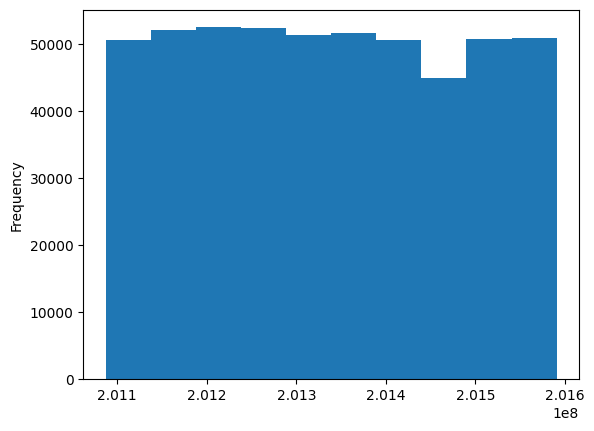

In [17]:
df_all['Incident ID'].plot(kind = 'hist')

In [20]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
df.sample(100)

,Incident ID,Offense Code,CR Number,Dispatch Date/Time,Start Date/Time,End Date/Time,NIBRS Code,Victims,Crime Name 1,Crime Name 2,Crime Name 3,Police District Name,Block Address,City,State,Zip Code,Agency,Place,Sector,Beat,PRA,Address Number,Street Prefix,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Geolocation
433875,201158956,3806,170538761,2017-10-25 12:45:45,2017-10-25 12:45:00,NaT,90F,1,Crime Against Society,"Family Offenses, NonViolent",FAMILY OFFENSE - NEGLECT CHILD (INCLUDES NONSU...,WHEATON,13600 BLK CONNECTICUT AVE,SILVER SPRING,MD,20906.0,MCPD,Parking Lot - Commercial,K,4K2,337,13600.0,NaN,CONNECTICUT,NaN,AVE,39.07762,-77.0809,4D,"(39.0776, -77.0809)"
343822,201245293,3615,190030241,2019-06-24 23:45:10,2019-06-24 13:41:00,2019-06-24 13:41:00,90C,1,Crime Against Society,Disorderly Conduct,SEX OFFENSE - INDECENT EXPOSURE TO ADULT,ROCKVILLE,200 BLK MEADOW HALL DR,ROCKVILLE,MD,20851.0,RCPD,Parking Lot - Other,A,1A2,293,200.0,NaN,MEADOW HALL,NaN,DR,39.07435,-77.1137,1D,"(39.0744, -77.1137)"
245591,201340270,1399,210029970,2021-08-02 15:08:48,2021-07-31 15:08:00,NaT,13B,1,Crime Against Person,Simple Assault,ASSAULT - 2ND DEGREE,SILVER SPRING,8300 BLK GEORGIA AVE,SILVER SPRING,MD,20910.0,MCPD,Bar/Night Club,G,3G1,670,8300.0,NaN,GEORGIA,NaN,AVE,38.99297,-77.0266,3D,"(38.993, -77.0266)"
353213,201236258,2902,190018784,2019-04-22 09:58:12,2019-04-22 09:58:00,NaT,290,1,Crime Against Property,Destruction/Damage/Vandalism of Property,DAMAGE PROPERTY - PRIVATE,BETHESDA,7600 BLK GLENBROOK RD,BETHESDA,MD,20814.0,MCPD,Residence - Yard,E,2E2,029,7600.0,NaN,GLENBROOK,NaN,RD,38.98574,-77.1076,2D,"(38.9857, -77.1076)"
247890,201337938,2304,210026968,2021-07-13 10:49:02,2021-07-13 08:00:00,2021-07-13 10:30:00,23G,1,Crime Against Property,Theft of Motor Vehicle Parts or Accessories,LARCENY - AUTO PARTS,BETHESDA,2400 BLK LYTTONSVILLE RD,SILVER SPRING,MD,20910.0,MCPD,Parking Lot - Residential,D,2D1,085,2400.0,NaN,LYTTONSVILLE,NaN,RD,39.00024,-77.0499,2D,"(39.0002, -77.0499)"
494558,201100319,2305,16049451,NaT,2016-09-25 18:00:00,2016-09-26 07:30:00,23F,1,Crime Against Property,Theft From Motor Vehicle,LARCENY - FROM AUTO,MONTGOMERY VILLAGE,20300 BLK STEDMALL PL,MONTGOMERY VILLAGE,MD,20886.0,MCPD,Residence - Driveway,R,6R2,714,20300.0,NaN,STEDMALL,NaN,PL,39.18843,-77.1720,6D,"(39.1884, -77.172)"
312753,201275172,2304,200004298,2020-01-26 13:44:30,2020-01-25 17:00:00,2020-01-26 00:00:00,23G,1,Crime Against Property,Theft of Motor Vehicle Parts or Accessories,LARCENY - AUTO PARTS,MONTGOMERY VILLAGE,600 BLK SUNNY BROOK TER,GAITHERSBURG,MD,20877.0,MCPD,Parking Lot - Residential,P,6P3,419,600.0,NaN,SUNNY BROOK,NaN,TER,39.15286,-77.1766,6D,"(39.1529, -77.1766)"
256997,201329198,9101,210016267,2021-05-01 14:01:09,2021-05-01 14:01:00,NaT,90Z,1,Crime Against Society,All Other Offenses,SUDDEN DEATH,MONTGOMERY VILLAGE,1 BLK SEABROOK CT,MONTGOMERY VILLAGE,MD,20886.0,MCPD,Residence - Single Family,R,6R2,714,1.0,NaN,SEABROOK,NaN,CT,39.18664,-77.1553,6D,"(39.1866, -77.1553)"
362435,201227466,2303,190007923,2019-02-19 00:24:24,2019-02-19 00:22:00,2019-02-19 00:24:00,23C,1,Crime Against Property,Shoplifting,LARCENY - SHOPLIFTING,SILVER SPRING,10200 BLK NEW HAMPSHIRE AVE,SILVER SPRING,MD,20903.0,MCPD,Convenience Store,H,3H2,141,10200.0,NaN,NEW HAMPSHIRE,NaN,AVE,39.02224,-76.9774,3D,"(39.0222, -76.9774)"
12044,201577946,1399,260024599,2026-06-04 19:34:43,2026-06-04 19:34:00,NaT,13B,1,Crime Against Person,Simple Assault,ASSAULT - 2ND DEGREE,ROCKVILLE,11300 BLK SEVEN LOCKS RD,POTOMAC,MD,20854.0,MCPD,Restaurant,B,1B1,203,11300.0,NaN,SEVEN LOCKS,NaN,RD,39.04070,-77.1590,1D,"(39.0407, -77.159)"
